# Stage 6 - Exploratory Data Analysis
**Project:** Personalized Movie Recommendation System Using Collaborative Filtering (No. 28)
**Data:** `data/processed/dataset.csv` (5,000 ratings; synthetic extension of the provided file, see `docs/data_source.md`)
**Target user:** a streaming viewer who wants relevant AND varied movies.

Each chart has a title, axis labels, a computed **INSIGHT** and the **DECISION** it drives for the models or the ethics audit.
Seven charts and five hypothesis tests. The notebook runs top to bottom.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100
SEED = 42; rng = np.random.default_rng(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data/processed/dataset.csv", parse_dates=["timestamp"])
cat = pd.read_csv(ROOT / "data/raw/movie_catalogue.csv")
INSIGHTS = []

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

def insight(text, decision):
    INSIGHTS.append((text, decision))
    print("INSIGHT :", text); print("DECISION:", decision)

print(df.shape, "| users", df.user_id.nunique(), "| movies", df.movie_id.nunique())

(5000, 9) | users 309 | movies 126


## 1. How are ratings distributed?
*Business question: what does a typical rating look like, and what should count as a "relevant" movie?*

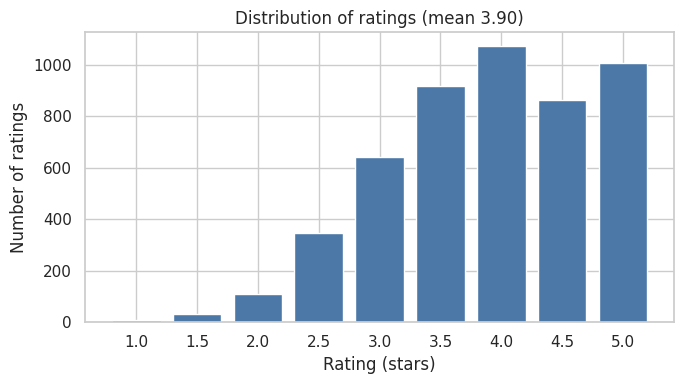

INSIGHT : Ratings are skewed towards high values: mean 3.90, median 4.0, skew -0.44; 58.8% of ratings are >= 4.0 and only 3.0% are <= 2.0.
DECISION: Because most ratings are high, mean baselines are strong and RMSE gains will be modest. Define 'relevant' as rating >= 4.0 for precision@K and recall@K.


In [2]:
counts = df.rating.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(counts.index.astype(str), counts.values, color="#4C78A8")
ax.set_title(f"Distribution of ratings (mean {df.rating.mean():.2f})")
ax.set_xlabel("Rating (stars)"); ax.set_ylabel("Number of ratings")
save("eda_01_rating_distribution")
insight(f"Ratings are skewed towards high values: mean {df.rating.mean():.2f}, median {df.rating.median():.1f}, skew {df.rating.skew():.2f}; "
        f"{(df.rating >= 4).mean():.1%} of ratings are >= 4.0 and only {(df.rating <= 2).mean():.1%} are <= 2.0.",
        "Because most ratings are high, mean baselines are strong and RMSE gains will be modest. Define 'relevant' as rating >= 4.0 for precision@K and recall@K.")

## 2. Is there a long tail of popularity, and how active are users?
*Business question: do a few blockbusters dominate, and are there enough ratings per user to learn from?*

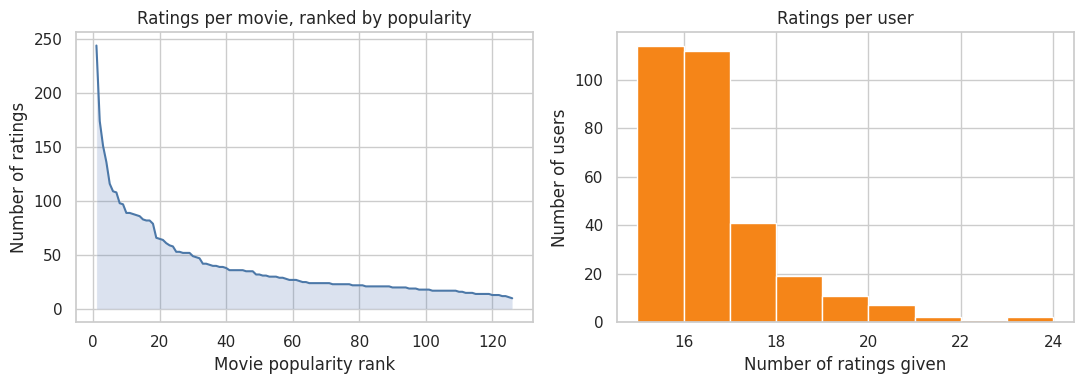

INSIGHT : Popularity is concentrated: the top 10% of movies receive 31.7% of ratings (Gini 0.40); the most rated movie has 244 ratings while 32 of 126 movies have fewer than 20. Users give 15-23 ratings (median 16).
DECISION: A popularity recommender will be a strong baseline. Thin movies are cold-start risks: use similarity shrinkage and a minimum-support rule, and report long-tail exposure in the diversity audit.


In [3]:
pi = df.groupby("movie_id").size().sort_values(ascending=False)
pu = df.groupby("user_id").size()
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())
top10 = pi.head(round(len(pi) * .1)).sum() / pi.sum()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(pi) + 1), pi.values, color="#4C78A8"); ax[0].fill_between(range(1, len(pi) + 1), pi.values, alpha=.2)
ax[0].set_title("Ratings per movie, ranked by popularity"); ax[0].set_xlabel("Movie popularity rank"); ax[0].set_ylabel("Number of ratings")
ax[1].hist(pu, bins=range(pu.min(), pu.max() + 2), color="#F58518", edgecolor="white")
ax[1].set_title("Ratings per user"); ax[1].set_xlabel("Number of ratings given"); ax[1].set_ylabel("Number of users")
save("eda_02_long_tail")
insight(f"Popularity is concentrated: the top 10% of movies receive {top10:.1%} of ratings (Gini {gini(pi):.2f}); the most rated movie has {pi.max()} ratings "
        f"while {(pi < 20).sum()} of {len(pi)} movies have fewer than 20. Users give {pu.min()}-{pu.max()} ratings (median {pu.median():.0f}).",
        "A popularity recommender will be a strong baseline. Thin movies are cold-start risks: use similarity shrinkage and a minimum-support rule, and report long-tail exposure in the diversity audit.")

## 3. How sparse is the user-item matrix, and do users overlap?
*Business question: can we find similar users / similar movies from so few ratings?*

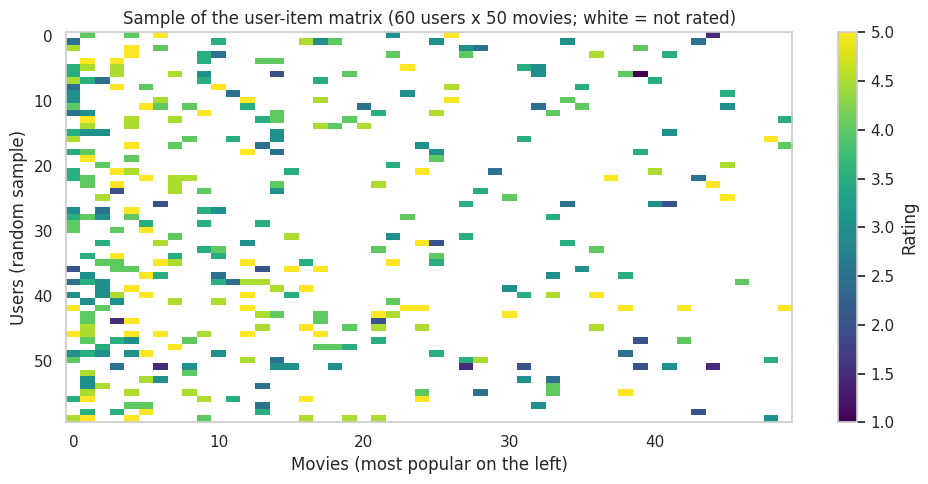

INSIGHT : Overall density is 12.8% (a typical user rated 16 of 126 movies). Two random users share a median of 4 rated movies (0.8% of user pairs share none, only 28.0% share 5+). Two random movies share a median of 3 raters.
DECISION: Overlap is modest in both directions (users and movies), so similarity estimates are noisy: use shrinkage/min-support in user-based and item-based CF, and compare them with SVD, which factorises the sparse matrix, in Stage 9.


In [4]:
M = df.pivot(index="user_id", columns="movie_id", values="rating")
pop_order = list(df.movie_id.value_counts().index)
users_s = rng.choice(M.index.to_numpy(), 60, replace=False)
movies_s = sorted(rng.choice(pop_order, 50, replace=False), key=pop_order.index)
S = M.loc[users_s, movies_s]
cmap = plt.get_cmap("viridis").copy(); cmap.set_bad("white")
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(np.ma.masked_invalid(S.values), aspect="auto", cmap=cmap, vmin=1, vmax=5)
ax.grid(False)
ax.set_title("Sample of the user-item matrix (60 users x 50 movies; white = not rated)")
ax.set_xlabel("Movies (most popular on the left)"); ax.set_ylabel("Users (random sample)")
plt.colorbar(im, ax=ax, label="Rating")
save("eda_03_matrix_sparsity")

B = M.notna().astype(int).to_numpy()
ou = (B @ B.T)[np.triu_indices(len(B), 1)]; oi = (B.T @ B)[np.triu_indices(B.shape[1], 1)]
insight(f"Overall density is {B.mean():.1%} (a typical user rated {B.sum(1).mean():.0f} of {B.shape[1]} movies). Two random users share a median of {np.median(ou):.0f} rated movies "
        f"({(ou == 0).mean():.1%} of user pairs share none, only {(ou >= 5).mean():.1%} share 5+). Two random movies share a median of {np.median(oi):.0f} raters.",
        "Overlap is modest in both directions (users and movies), so similarity estimates are noisy: use shrinkage/min-support in user-based and item-based CF, and compare them with SVD, which factorises the sparse matrix, in Stage 9.")

## 4. Which genres and languages are watched, relative to what exists?
*Business question: does attention follow the catalogue, or do some languages/genres get less than their share? (diversity baseline)*

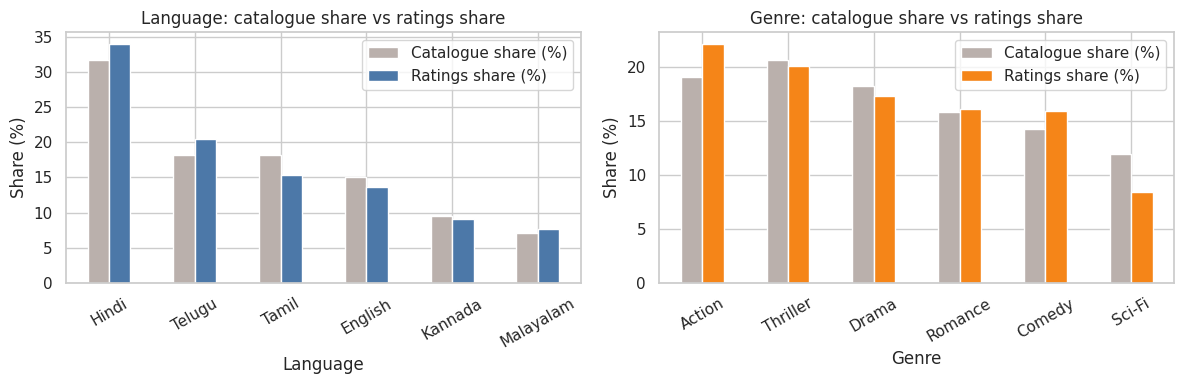

INSIGHT : Hindi is 31.7% of the catalogue and 34.0% of ratings. Largest language gaps: Hindi +2.2 pp, Tamil -2.9 pp. Largest genre gaps: Action +3.1 pp, Sci-Fi -3.5 pp. Southern regional languages (Tamil, Telugu, Kannada, Malayalam) are 53.2% of the catalogue and 52.4% of ratings.
DECISION: Use these shares as the baseline for the diversity audit: a fair recommender should keep regional-language and genre shares in recommendations close to the catalogue, not only to what is already most rated.


In [5]:
def share_table(col):
    c = cat[col].value_counts(normalize=True) * 100
    r = df[col].value_counts(normalize=True) * 100
    return pd.DataFrame({"Catalogue share (%)": c, "Ratings share (%)": r}).fillna(0).sort_values("Ratings share (%)", ascending=False)
lang_t, genre_t = share_table("language"), share_table("genre")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lang_t.plot.bar(ax=ax[0], color=["#BAB0AC", "#4C78A8"]); ax[0].set_title("Language: catalogue share vs ratings share"); ax[0].set_xlabel("Language"); ax[0].set_ylabel("Share (%)")
genre_t.plot.bar(ax=ax[1], color=["#BAB0AC", "#F58518"]); ax[1].set_title("Genre: catalogue share vs ratings share"); ax[1].set_xlabel("Genre"); ax[1].set_ylabel("Share (%)")
for a in ax: a.tick_params(axis="x", rotation=30)
save("eda_04_genre_language_share")
gap = lang_t["Ratings share (%)"] - lang_t["Catalogue share (%)"]; gg = genre_t["Ratings share (%)"] - genre_t["Catalogue share (%)"]
reg = ["Tamil", "Telugu", "Kannada", "Malayalam"]
insight(f"Hindi is {lang_t.loc['Hindi', 'Catalogue share (%)']:.1f}% of the catalogue and {lang_t.loc['Hindi', 'Ratings share (%)']:.1f}% of ratings. "
        f"Largest language gaps: {gap.idxmax()} {gap.max():+.1f} pp, {gap.idxmin()} {gap.min():+.1f} pp. Largest genre gaps: {gg.idxmax()} {gg.max():+.1f} pp, {gg.idxmin()} {gg.min():+.1f} pp. "
        f"Southern regional languages (Tamil, Telugu, Kannada, Malayalam) are {lang_t.loc[reg, 'Catalogue share (%)'].sum():.1f}% of the catalogue and {lang_t.loc[reg, 'Ratings share (%)'].sum():.1f}% of ratings.",
        "Use these shares as the baseline for the diversity audit: a fair recommender should keep regional-language and genre shares in recommendations close to the catalogue, not only to what is already most rated.")

## 5. Do some languages or genres get higher ratings?
*Business question: are genre/language averages useful predictors on their own?*

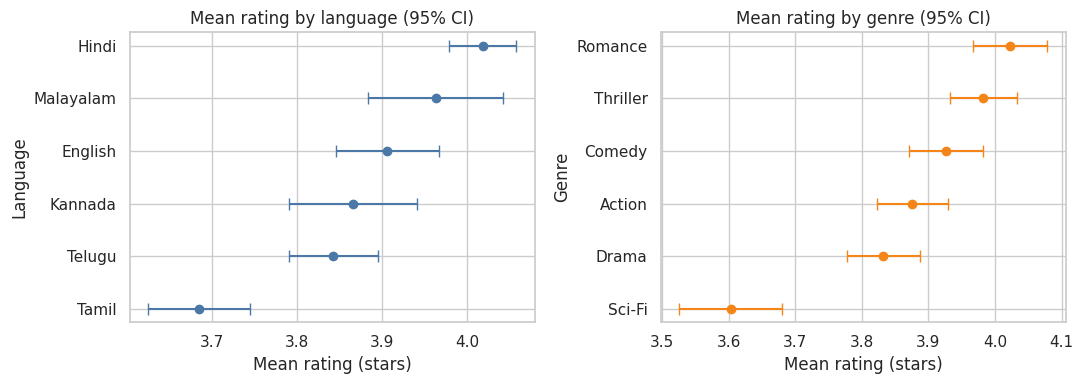

INSIGHT : Language means range 3.69 (Tamil) to 4.02 (Hindi); genre means range 3.60 (Sci-Fi) to 4.02 (Romance). Overall mean is 3.90.
DECISION: Group averages shift ratings by only a few tenths of a star. Keep genre/language for diversity metrics and cold-start fallback, not as the main predictor; personalisation has to come from user-item patterns.


In [6]:
def mean_ci(col):
    g = df.groupby(col).rating.agg(["mean", "sem", "count"]); g["ci"] = 1.96 * g["sem"]
    return g.sort_values("mean")
lm, gm = mean_ci("language"), mean_ci("genre")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, t, name, c in [(ax[0], lm, "language", "#4C78A8"), (ax[1], gm, "genre", "#F58518")]:
    a.errorbar(t["mean"], range(len(t)), xerr=t["ci"], fmt="o", color=c, capsize=4)
    a.set_yticks(range(len(t))); a.set_yticklabels(t.index)
    a.set_title(f"Mean rating by {name} (95% CI)"); a.set_xlabel("Mean rating (stars)"); a.set_ylabel(name.capitalize())
save("eda_05_mean_rating_by_group")
insight(f"Language means range {lm['mean'].min():.2f} ({lm['mean'].idxmin()}) to {lm['mean'].max():.2f} ({lm['mean'].idxmax()}); genre means range "
        f"{gm['mean'].min():.2f} ({gm['mean'].idxmin()}) to {gm['mean'].max():.2f} ({gm['mean'].idxmax()}). Overall mean is {df.rating.mean():.2f}.",
        "Group averages shift ratings by only a few tenths of a star. Keep genre/language for diversity metrics and cold-start fallback, not as the main predictor; personalisation has to come from user-item patterns.")

## 6. How do activity and ratings change over time?
*Business question: how should we split train and test without leaking the future?*

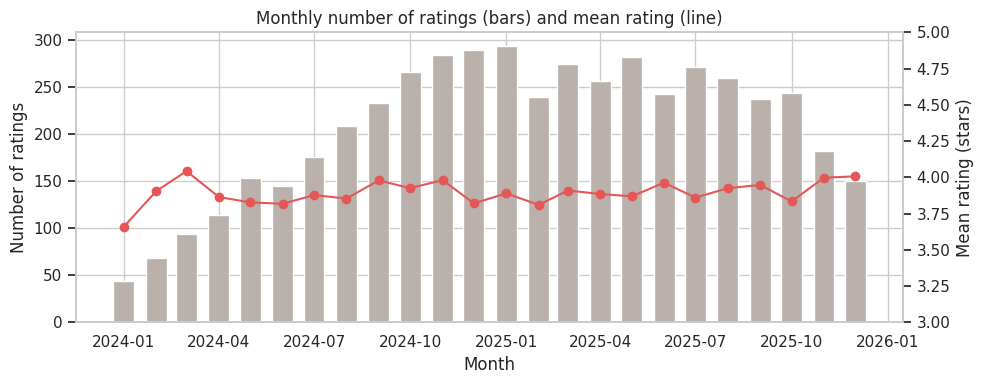

INSIGHT : Activity ramps up from 44 ratings in Jan 2024 to a peak of 293 in Jan 2025, then declines to 150 by Dec 2025; the monthly mean rating stays between 3.66 and 4.04. (The ramp comes from each synthetic user's activity window.)
DECISION: Rating level is stable over time, but volume is not. Use a per-user chronological split (each user's latest 20% of ratings as test) instead of one global cut-off, so every user is in both train and test and nothing from the future enters training.


In [7]:
mo = df.set_index("timestamp").rating.resample("MS").agg(["count", "mean"])
fig, ax = plt.subplots(figsize=(10, 4)); ax2 = ax.twinx()
ax.bar(mo.index, mo["count"], width=20, color="#BAB0AC")
ax2.plot(mo.index, mo["mean"], color="#E45756", marker="o"); ax2.set_ylim(3, 5); ax2.grid(False)
ax.set_title("Monthly number of ratings (bars) and mean rating (line)"); ax.set_xlabel("Month"); ax.set_ylabel("Number of ratings"); ax2.set_ylabel("Mean rating (stars)")
save("eda_06_ratings_over_time")
pk = mo["count"].idxmax()
insight(f"Activity ramps up from {mo['count'].iloc[0]} ratings in {mo.index[0]:%b %Y} to a peak of {mo['count'].max()} in {pk:%b %Y}, then declines to {mo['count'].iloc[-1]} by {mo.index[-1]:%b %Y}; "
        f"the monthly mean rating stays between {mo['mean'].min():.2f} and {mo['mean'].max():.2f}. (The ramp comes from each synthetic user's activity window.)",
        "Rating level is stable over time, but volume is not. Use a per-user chronological split (each user's latest 20% of ratings as test) instead of one global cut-off, so every user is in both train and test and nothing from the future enters training.")

## 7. Do users and movies differ in how generously they are rated?
*Business question: do we need to correct for rating-scale bias?*

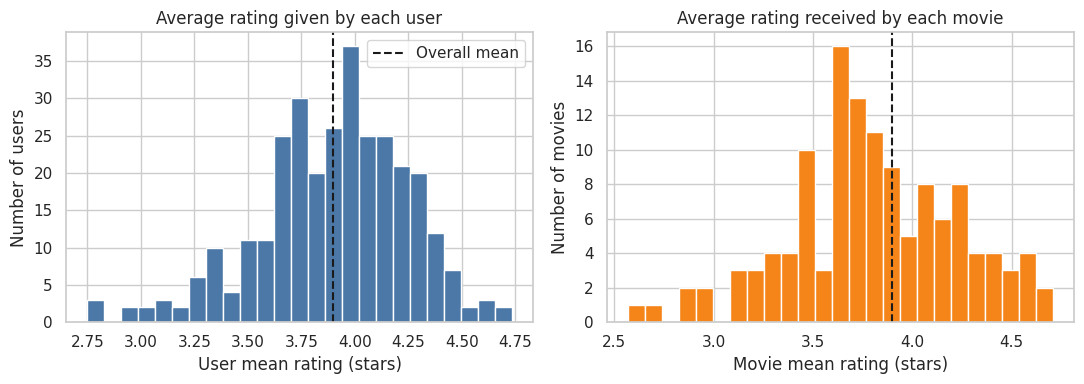

INSIGHT : User mean ratings range 2.75-4.73 (std 0.35); movie mean ratings range 2.57-4.71 (std 0.43).
DECISION: Both generous users and well-liked movies exist, so predictions must include user and movie biases. Mean-centre ratings in the kNN models and use bias terms in SVD; compare against the baseline mu + b_user + b_item.


In [8]:
um = df.groupby("user_id").rating.mean(); im = df.groupby("movie_id").rating.mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(um, bins=25, color="#4C78A8", edgecolor="white"); ax[0].axvline(df.rating.mean(), color="k", ls="--", label="Overall mean"); ax[0].legend()
ax[0].set_title("Average rating given by each user"); ax[0].set_xlabel("User mean rating (stars)"); ax[0].set_ylabel("Number of users")
ax[1].hist(im, bins=25, color="#F58518", edgecolor="white"); ax[1].axvline(df.rating.mean(), color="k", ls="--")
ax[1].set_title("Average rating received by each movie"); ax[1].set_xlabel("Movie mean rating (stars)"); ax[1].set_ylabel("Number of movies")
save("eda_07_user_movie_bias")
insight(f"User mean ratings range {um.min():.2f}-{um.max():.2f} (std {um.std():.2f}); movie mean ratings range {im.min():.2f}-{im.max():.2f} (std {im.std():.2f}).",
        "Both generous users and well-liked movies exist, so predictions must include user and movie biases. Mean-centre ratings in the kNN models and use bias terms in SVD; compare against the baseline mu + b_user + b_item.")

## 8. Five hypotheses and tests
Significance level 0.05. Effect sizes are reported because with 5,000 ratings almost anything is "significant".

**Honesty note:** the synthetic generator deliberately built in user bias, movie bias, genre/language taste and popularity. Confirming them shows the data behaves as designed and has something for the models to learn. It is **not** evidence about real viewers.

In [9]:
res = []
def strength(x, kind):
    x = abs(x)
    cuts = {"rho": (.1, .3, .5), "eps": (.01, .06, .14), "eta": (.01, .06, .14)}[kind]
    return ["negligible", "small/weak", "medium/moderate", "large/strong"][sum(x >= c for c in cuts)]

# H1: more popular movies are rated higher
pm = df.groupby("movie_id").rating.agg(["count", "mean"])
rho, p = stats.spearmanr(pm["count"], pm["mean"])
res.append(["H1", "Movies with more ratings have higher mean rating", "Spearman correlation", f"rho = {rho:.2f}", p, f"rho = {rho:.2f} ({strength(rho, 'rho')})"])

# H2 / H3: rating differs across languages / genres (Kruskal-Wallis, epsilon-squared)
for h, col in [("H2", "language"), ("H3", "genre")]:
    H, p = stats.kruskal(*[g.rating.values for _, g in df.groupby(col)])
    eps = H / (len(df) - 1)
    res.append([h, f"Ratings differ across {col}s", "Kruskal-Wallis", f"H = {H:.1f}", p, f"eps2 = {eps:.3f} ({strength(eps, 'eta')})"])

# H4: users differ in how generously they rate (one-way ANOVA, eta-squared)
groups = [g.rating.values for _, g in df.groupby("user_id")]
F, p = stats.f_oneway(*groups)
ss_b = sum(len(g) * (g.mean() - df.rating.mean()) ** 2 for g in groups); ss_t = ((df.rating - df.rating.mean()) ** 2).sum()
k, N = len(groups), len(df); ms_w = (ss_t - ss_b) / (N - k)
eta = (ss_b - (k - 1) * ms_w) / (ss_t + ms_w)   # omega-squared: eta-squared is inflated when there are many small groups
res.append(["H4", "Users differ in average rating given", "One-way ANOVA", f"F = {F:.2f}", p, f"omega2 = {eta:.3f} ({strength(eta, 'eta')})"])

# H5: users concentrate on fewer languages than popularity alone would produce (permutation test)
codes_item = pd.factorize(cat.language)[0]; K = codes_item.max() + 1
item_ids = list(cat.movie_id); idx = {m: i for i, m in enumerate(item_ids)}
w = df.movie_id.map(idx).value_counts().reindex(range(len(item_ids))).fillna(0).to_numpy(); w = w / w.sum()
def ent(c):
    p_ = np.bincount(c, minlength=K) / len(c); p_ = p_[p_ > 0]; return -(p_ * np.log2(p_)).sum()
user_items = df.groupby("user_id").movie_id.apply(lambda s: [idx[m] for m in s])
obs = np.mean([ent(codes_item[v]) for v in user_items])
SIMS = 300; null = np.empty(SIMS)
for s in range(SIMS):
    null[s] = np.mean([ent(codes_item[rng.choice(len(w), size=len(v), replace=False, p=w)]) for v in user_items])
p = (np.sum(null <= obs) + 1) / (SIMS + 1)
res.append(["H5", "Users' language mix is less varied than popularity alone predicts", "Permutation test (300 sims)", f"obs {obs:.3f} vs null {null.mean():.3f} bits", p, f"drop {null.mean() - obs:.3f} bits (max {np.log2(K):.2f})"])

H = pd.DataFrame(res, columns=["ID", "Hypothesis", "Test", "Statistic", "p-value", "Effect size"])
H["Result (alpha 0.05)"] = np.where(H["p-value"] < .05, "Reject H0", "Not rejected")
H["p-value"] = H["p-value"].map(lambda v: f"{v:.2e}")
pd.set_option("display.width", 200, "display.max_colwidth", 70)
H

,ID,Hypothesis,Test,Statistic,p-value,Effect size,Result (alpha 0.05)
0,H1,Movies with more ratings have higher mean rating,Spearman correlation,rho = 0.20,2.59e-02,rho = 0.20 (small/weak),Reject H0
1,H2,Ratings differ across languages,Kruskal-Wallis,H = 93.7,1.10e-18,eps2 = 0.019 (small/weak),Reject H0
2,H3,Ratings differ across genres,Kruskal-Wallis,H = 89.5,8.70e-18,eps2 = 0.018 (small/weak),Reject H0
3,H4,Users differ in average rating given,One-way ANOVA,F = 3.21,3.12e-63,omega2 = 0.120 (medium/moderate),Reject H0
4,H5,Users' language mix is less varied than popularity alone predicts,Permutation test (300 sims),obs 2.172 vs null 2.199 bits,2.33e-02,drop 0.027 bits (max 2.58),Reject H0


In [10]:
rows = {r[0]: r for r in res}
insight(f"H1 popularity vs rating: {rows['H1'][5]}, p = {rows['H1'][4]:.3f}. Popular movies are rated slightly higher, but the link is weak.",
        "Popularity is only a weak signal of quality; keep it as a ranking baseline but do not rely on it.")
insight(f"H2/H3 language and genre: effect sizes {rows['H2'][5]} and {rows['H3'][5]}. Differences are statistically real but small.",
        "Consistent with chart 5: use genre/language for diversity and cold-start only.")
insight(f"H4 user generosity: {rows['H4'][5]}, F = {rows['H4'][3].split('= ')[1]}. Which user is rating explains a sizeable share of rating variance (bias-corrected omega-squared; plain eta-squared would overstate it with 309 small groups).",
        "User bias is the strongest simple signal: mean-centring and the user-bias baseline are mandatory.")
insight(f"H5 filter-bubble risk: users' languages are slightly less varied than popularity alone predicts ({rows['H5'][3]}, p = {rows['H5'][4]:.4f}); the effect is small ({rows['H5'][5]}).",
        "Taste concentration is mild in this data, but CF amplifies whatever concentration exists. Measure language/genre diversity of recommendations and test a re-ranker in Stage 10.")

INSIGHT : H1 popularity vs rating: rho = 0.20 (small/weak), p = 0.026. Popular movies are rated slightly higher, but the link is weak.
DECISION: Popularity is only a weak signal of quality; keep it as a ranking baseline but do not rely on it.
INSIGHT : H2/H3 language and genre: effect sizes eps2 = 0.019 (small/weak) and eps2 = 0.018 (small/weak). Differences are statistically real but small.
DECISION: Consistent with chart 5: use genre/language for diversity and cold-start only.
INSIGHT : H4 user generosity: omega2 = 0.120 (medium/moderate), F = 3.21. Which user is rating explains a sizeable share of rating variance (bias-corrected omega-squared; plain eta-squared would overstate it with 309 small groups).
DECISION: User bias is the strongest simple signal: mean-centring and the user-bias baseline are mandatory.
INSIGHT : H5 filter-bubble risk: users' languages are slightly less varied than popularity alone predicts (obs 2.172 vs null 2.199 bits, p = 0.0233); the effect is small (drop 

## 9. Summary of insights and decisions

In [11]:
lines = ["# EDA insights (auto-generated by notebooks/03_eda.ipynb)", ""]
for i, (t, d) in enumerate(INSIGHTS, 1):
    lines += [f"{i}. **Insight:** {t}", f"   **Decision:** {d}", ""]
(ROOT / "docs" / "eda_insights.md").write_text("\n".join(lines))
print("\n".join(lines))

# EDA insights (auto-generated by notebooks/03_eda.ipynb)

1. **Insight:** Ratings are skewed towards high values: mean 3.90, median 4.0, skew -0.44; 58.8% of ratings are >= 4.0 and only 3.0% are <= 2.0.
   **Decision:** Because most ratings are high, mean baselines are strong and RMSE gains will be modest. Define 'relevant' as rating >= 4.0 for precision@K and recall@K.

2. **Insight:** Popularity is concentrated: the top 10% of movies receive 31.7% of ratings (Gini 0.40); the most rated movie has 244 ratings while 32 of 126 movies have fewer than 20. Users give 15-23 ratings (median 16).
   **Decision:** A popularity recommender will be a strong baseline. Thin movies are cold-start risks: use similarity shrinkage and a minimum-support rule, and report long-tail exposure in the diversity audit.

3. **Insight:** Overall density is 12.8% (a typical user rated 16 of 126 movies). Two random users share a median of 4 rated movies (0.8% of user pairs share none, only 28.0% share 5+). Two ra